
# Document-Aligned VDBI-VBTNet for Adaptive E-Commerce Churn Intelligence

**Project:** *Decoding Individualized Purchase Behavior for Variance-Driven Adaptive Churn Intelligence in E-Commerce Platforms*

**Dataset used in this implementation:** UCI Online Retail II  
**Model policy:** Only the proposed **Variance-Driven Behavioral Intelligence (VDBI) + Variance-Aware Behavioral Transformer Network (VBTNet)** is trained. No baseline/comparison model is trained.

## Alignment with the supplied APA/IEEE methodology

This notebook follows the paper's main methodological sequence:

1. Intelligent preprocessing
2. Individualized purchase behavior analysis
3. Multi-dimensional behavioral feature engineering
4. VDBI: purchase variance, spending volatility, behavioral drift, customer stability
5. VBTNet with **5 attention heads**, **embedding dimension = 10**, and **per-head key/query dimension = 2**
6. Adaptive fusion initialized at **λ = 0.60**
7. Softmax churn classification
8. 68% / 12% / 20% stratified train-validation-test split
9. Accuracy, Precision, Recall, F1, AUC, MCC, Balanced Accuracy
10. ROC, PR, calibration, threshold, confusion matrix, probability and risk analyses
11. Attention and latent-representation analyses
12. SHAP, permutation importance and information-gain analyses

### Dataset-adaptation note
Online Retail II contains real transactions but does **not** contain login frequency, session duration, email opens, mobile-app use, social-media engagement or cart abandonment. These variables are **not fabricated**. Instead, a **Transaction Engagement Index (TEI)** and purchase-efficiency measures are derived from genuine purchase activity, active days, purchase lines, recent activity and return behavior.

### Temporal churn definition used here
- Observation period: December 2009 to May 2011
- Future outcome period: June 2011 to 9 December 2011
- **Churned = 1:** no positive future purchase invoice
- **Retained = 0:** at least 6 future positive purchase invoices
- Customers with 1-5 future invoices are excluded as an ambiguous low-frequency retention group.

This high-confidence outcome definition is used to reduce label noise while preserving a genuine future prediction task.


In [1]:

import os, sys, gc, math, random, warnings, zipfile
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from openpyxl import load_workbook

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, balanced_accuracy_score,
    matthews_corrcoef, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve
)
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
from sklearn.manifold import TSNE, SpectralEmbedding
from sklearn.metrics.pairwise import cosine_similarity

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

import shap

warnings.filterwarnings("ignore")

SEED = 12
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams["figure.figsize"] = (9, 5.5)
plt.rcParams["axes.titleweight"] = "bold"


def apply_plot_format(ax=None, x_rotation=90, legend_above=True):
    """Apply the requested publication-style formatting to every figure."""
    if ax is None:
        ax = plt.gca()

    # Rotate every x-axis tick label to 90 degrees.
    for tick in ax.get_xticklabels():
        tick.set_rotation(x_rotation)
        tick.set_horizontalalignment("center")
        tick.set_verticalalignment("top")

    # Preserve and reposition the existing legend above the plotting area.
    legend = ax.get_legend()
    has_legend = legend is not None
    if legend_above and has_legend:
        legend.set_bbox_to_anchor((0.5, 1.16), transform=ax.transAxes)
        # Matplotlib location code 8 = lower center; keeps the legend above the axes.
        legend._loc = 8
        try:
            legend.set_ncols(min(4, max(1, len(legend.get_texts()))))
        except Exception:
            pass
        legend.set_frame_on(True)

    fig = ax.figure
    # Fit long 90-degree labels first, then reserve dedicated top whitespace.
    fig.tight_layout()
    if legend_above and has_legend:
        fig.subplots_adjust(top=0.70)
    return ax


print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Seaborn:", sns.__version__)
print("PyTorch:", torch.__version__)
print("SHAP:", shap.__version__)
print("Random seed:", SEED)


/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-p4o067ei because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Python: 3.13.5
NumPy: 2.3.5
Pandas: 2.2.3
Seaborn: 0.13.2
PyTorch: 2.10.0+cpu
SHAP: 0.50.0
Random seed: 12


/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:

# Publication-level visualization formatter
# Rules:
# 1. X-axis labels remain 0 degree by default.
# 2. Rotate only when neighbouring labels overlap.
# 3. Legends stay inside the graph box at the top-right.
# 4. Avoid covering plotted elements.

def publication_format(ax):
    fig = ax.figure

    # ---- Adaptive x-axis rotation ----
    fig.canvas.draw()
    labels = ax.get_xticklabels()

    overlap = False
    if len(labels) > 1:
        renderer = fig.canvas.get_renderer()
        boxes = [
            label.get_window_extent(renderer=renderer)
            for label in labels if label.get_text()
        ]
        for i in range(len(boxes)-1):
            if boxes[i].overlaps(boxes[i+1]):
                overlap = True
                break

    if overlap:
        ax.tick_params(axis="x", rotation=90)
        plt.subplots_adjust(bottom=0.30)
    else:
        ax.tick_params(axis="x", rotation=0)

    # ---- Legend inside top-right corner ----
    legend = ax.get_legend()
    if legend is not None:
        legend.set_bbox_to_anchor((0.98, 0.98))
        legend.set_loc("upper right")
        legend.set_frame_on(True)

        # Reduce legend size to avoid congestion
        for text in legend.get_texts():
            text.set_fontsize(9)

    # ---- Keep values/text within graph area ----
    ax.margins(y=0.12)

    # Keep title away from legend
    ax.set_title(ax.get_title(), pad=14)

    plt.tight_layout()


In [3]:

# Final presentation visualization helper
# Rules:
# - Keep x-axis horizontal by default
# - Rotate only when labels collide with title/plot area
# - Keep legends inside top-right without covering plot content
# - Keep annotation text inside axes boundary

def presentation_format(ax):
    labels = [t.get_text() for t in ax.get_xticklabels()]

    # Default: 0 degree
    ax.tick_params(axis="x", rotation=0)

    # Rotate only genuinely long labels
    if any(len(str(x)) > 22 for x in labels):
        ax.tick_params(axis="x", rotation=90)
        plt.subplots_adjust(bottom=0.30)

    # Legend inside top-right
    legend = ax.get_legend()
    if legend is not None:
        legend.set_bbox_to_anchor((0.98, 0.98))
        legend._loc = 1
        legend.set_frame_on(True)
        plt.subplots_adjust(top=0.88)

    # Prevent values/text escaping graph box
    ax.margins(y=0.15)
    ax.set_clip_on(True)

    plt.tight_layout()


In [4]:

# Final visualization formatting helper
# - Rotate only long x-axis labels
# - Keep legends above plots
# - Keep annotations/value labels inside axes boundaries

def finalize_plot(ax, rotate_threshold=18):
    labels = [tick.get_text() for tick in ax.get_xticklabels()]
    if any(len(str(x)) > rotate_threshold for x in labels):
        ax.tick_params(axis="x", rotation=90)
        plt.subplots_adjust(bottom=0.32)
    else:
        ax.tick_params(axis="x", rotation=0)

    legend = ax.get_legend()
    if legend is not None:
        legend.set_bbox_to_anchor((0.5, 1.18))
        legend.set_loc("upper center")
        legend.set_ncols(min(3, len(legend.texts)))
        plt.subplots_adjust(top=0.80)

    # Keep annotations/text inside the plotting area
    ax.margins(y=0.12)
    plt.tight_layout()


In [5]:

# Locate the UCI Online Retail II workbook.
search_roots = [Path("/mnt/data"), Path("/content"), Path(".")]
xlsx_path = None
zip_path = None

for root in search_roots:
    p = root / "online_retail_II.xlsx"
    if p.exists():
        xlsx_path = p
        break

if xlsx_path is None:
    for root in search_roots:
        p = root / "online+retail+ii_dataset.zip"
        if p.exists():
            zip_path = p
            break

if xlsx_path is None and zip_path is not None:
    extract_dir = zip_path.parent / "online_retail_ii_extracted"
    extract_dir.mkdir(exist_ok=True)
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(extract_dir)
    candidates = list(extract_dir.rglob("online_retail_II.xlsx"))
    if candidates:
        xlsx_path = candidates[0]

if xlsx_path is None:
    raise FileNotFoundError(
        "Upload online_retail_II.xlsx or online+retail+ii_dataset.zip before running."
    )

print("Dataset:", xlsx_path)
print("Workbook size (MB):", round(xlsx_path.stat().st_size / 1024**2, 2))


Dataset: /mnt/data/online_retail_II.xlsx
Workbook size (MB): 43.51


In [6]:

# Inspect workbook structure without loading all 1M+ rows into memory.
wb = load_workbook(xlsx_path, read_only=True, data_only=True)

structure = []
for ws in wb.worksheets:
    header = [c.value for c in next(ws.iter_rows(min_row=1, max_row=1))]
    structure.append({
        "Sheet": ws.title,
        "Rows_excluding_header": ws.max_row - 1,
        "Columns": ws.max_column,
        "Fields": ", ".join(map(str, header)),
    })
wb.close()

structure_df = pd.DataFrame(structure)
display(structure_df)
print("Total raw transaction rows:", int(structure_df["Rows_excluding_header"].sum()))


,Sheet,Rows_excluding_header,Columns,Fields
0,Year 2009-2010,525461,8,"Invoice, StockCode, Description, Quantity, Inv..."
1,Year 2010-2011,541910,8,"Invoice, StockCode, Description, Quantity, Inv..."


Total raw transaction rows: 1067371



## 1. Transaction-to-Customer Temporal Construction

The raw data is transaction-level. For each eligible customer, the observation period is converted into an **18-month behavioral sequence**.

Monthly sequence variables:
- invoice count,
- spending,
- quantity,
- positive purchase lines,
- active purchase days,
- average order value,
- return/cancellation rate.

The customer-level features used later include recency, tenure, monetary value, recent behavior, behavioral trends and variance-related quantities.


In [7]:

OBS_START = datetime(2009, 12, 1)
OBS_END   = datetime(2011, 5, 31, 23, 59, 59)
OUT_START = datetime(2011, 6, 1)
OUT_END   = datetime(2011, 12, 9, 23, 59, 59)
N_MONTHS = 18

SEQ_FEATURES = [
    "Invoice_Count", "Spend", "Quantity", "Purchase_Lines",
    "Active_Days", "Average_Order_Value", "Return_Rate"
]

BASE_STATIC_FEATURES = [
    "Purchase_Variance", "Spending_Volatility", "Behavioral_Drift",
    "Customer_Stability", "Active_Month_Gap_Std", "Recency_Days",
    "Tenure_Days", "Total_Invoices", "Monetary_Value",
    "Purchase_Lines_Total", "Active_Days_Total", "Return_Rate_Total",
    "Frequency_Trend", "Spending_Trend", "Recent_3M_Invoices",
    "Previous_3M_Invoices", "Recent_3M_Spend", "Previous_3M_Spend",
    "Recent_Active_Months_6M", "Inactivity_Streak_Months"
]

cache_candidates = [
    Path("/mnt/data/vdbi_project_cache.npz"),
    Path("/content/vdbi_project_cache.npz"),
    Path("vdbi_project_cache.npz"),
]
cache_path = next((p for p in cache_candidates if p.exists()), None)

def build_features_from_xlsx(path):
    # Full fallback builder from the raw workbook.
    # The current executed notebook uses the validated cache generated from this logic.
    from collections import defaultdict

    def new_customer():
        return {
            "mat": np.zeros((N_MONTHS, 7), dtype=np.float32),
            "first": None, "last": None,
            "last_invoice": None, "last_day": None,
            "outcome_invoice_count": 0, "last_outcome_invoice": None
        }

    first_sheet_end = datetime(2010, 11, 30, 23, 59, 59)
    agg = defaultdict(new_customer)

    wb = load_workbook(path, read_only=True, data_only=True)
    for ws in wb.worksheets:
        for row in ws.iter_rows(min_row=2, values_only=True):
            invoice, stock, description, quantity, invoice_date, price, customer_id, country = row

            if customer_id is None or invoice_date is None or quantity is None or price is None:
                continue
            if ws.title == "Year 2009-2010" and invoice_date > first_sheet_end:
                # Remove the overlap between the two workbook sheets.
                continue

            try:
                cid = int(customer_id)
                qty = float(quantity)
                unit_price = float(price)
                inv = str(invoice)
            except Exception:
                continue

            is_purchase = qty > 0 and unit_price > 0 and not inv.upper().startswith("C")
            is_return = qty < 0 or inv.upper().startswith("C")
            a = agg[cid]

            if OBS_START <= invoice_date <= OBS_END:
                month_idx = (invoice_date.year - 2009) * 12 + invoice_date.month - 12
                if not (0 <= month_idx < N_MONTHS):
                    continue

                a["mat"][month_idx, 5] += 1
                if is_return:
                    a["mat"][month_idx, 6] += 1

                if is_purchase:
                    a["mat"][month_idx, 3] += 1

                    if a["last_invoice"] != inv:
                        a["mat"][month_idx, 0] += 1
                        a["last_invoice"] = inv

                    day = invoice_date.date()
                    if a["last_day"] != day:
                        a["mat"][month_idx, 4] += 1
                        a["last_day"] = day

                    a["mat"][month_idx, 1] += qty * unit_price
                    a["mat"][month_idx, 2] += qty

                    if a["first"] is None or invoice_date < a["first"]:
                        a["first"] = invoice_date
                    if a["last"] is None or invoice_date > a["last"]:
                        a["last"] = invoice_date

            elif OUT_START <= invoice_date <= OUT_END and is_purchase:
                if a["last_outcome_invoice"] != inv:
                    a["outcome_invoice_count"] += 1
                    a["last_outcome_invoice"] = inv

    wb.close()

    X_list, S_list, ids_list, outcome_counts = [], [], [], []

    for cid, a in agg.items():
        if a["last"] is None:
            continue

        mat = a["mat"]
        inv, spend, qty, plines, active_days, all_lines, returns = [mat[:, i] for i in range(7)]

        total_invoices = float(inv.sum())
        active_months = int((inv > 0).sum())

        # Minimum history needed for variance/drift estimation.
        if total_invoices < 4 or active_months < 3 or (OBS_END - a["first"]).days < 180:
            continue

        aov = np.divide(spend, inv, out=np.zeros_like(spend), where=inv > 0)
        return_rate = np.divide(returns, all_lines, out=np.zeros_like(returns), where=all_lines > 0)

        X_seq = np.column_stack([
            inv, spend, qty, plines, active_days, aov, return_rate
        ]).astype(np.float32)

        recency = float((OBS_END - a["last"]).days)
        tenure = float((OBS_END - a["first"]).days)
        purchase_variance = float(np.var(inv))
        spending_volatility = float(np.std(spend) / (np.mean(spend) + 1e-6))
        quantity_volatility = float(np.std(qty) / (np.mean(qty) + 1e-6))
        frequency_volatility = float(np.std(inv) / (np.mean(inv) + 1e-6))

        core = np.column_stack([inv, spend, qty, plines, active_days])
        core = core / np.maximum(core.mean(axis=0), 1e-6)
        behavioral_drift = float(
            np.linalg.norm(core[-3:].mean(axis=0) - core[:-3].mean(axis=0))
        )

        customer_stability = float(
            1.0 / (1.0 + spending_volatility + quantity_volatility + frequency_volatility)
        )

        active_idx = np.where(inv > 0)[0]
        active_gap_std = float(np.std(np.diff(active_idx))) if len(active_idx) > 2 else 0.0

        x = np.arange(N_MONTHS, dtype=np.float32)
        frequency_trend = float(np.polyfit(x, inv, 1)[0])
        spending_trend = float(np.polyfit(x, spend, 1)[0])

        inactivity_streak = 0
        for value in inv[::-1]:
            if value <= 0:
                inactivity_streak += 1
            else:
                break

        static = [
            purchase_variance, spending_volatility, behavioral_drift,
            customer_stability, active_gap_std, recency, tenure,
            total_invoices, float(spend.sum()), float(plines.sum()),
            float(active_days.sum()),
            float(returns.sum() / max(all_lines.sum(), 1)),
            frequency_trend, spending_trend,
            float(inv[-3:].sum()), float(inv[-6:-3].sum()),
            float(spend[-3:].sum()), float(spend[-6:-3].sum()),
            float((inv[-6:] > 0).sum()), float(inactivity_streak)
        ]

        X_list.append(X_seq)
        S_list.append(static)
        ids_list.append(cid)
        outcome_counts.append(a["outcome_invoice_count"])

    return (
        np.stack(X_list),
        np.asarray(S_list, dtype=np.float32),
        np.asarray(ids_list, dtype=np.int64),
        np.asarray(outcome_counts, dtype=np.int32),
    )

if cache_path is not None:
    cached = np.load(cache_path)
    X_all = cached["X"].astype(np.float32)
    S_base_all = cached["S"].astype(np.float32)
    customer_ids_all = cached["ids"].astype(np.int64)
    outcome_invoices_all = cached["outcome_invoices"].astype(np.int32)
    print("Loaded validated temporal customer cache:", cache_path)
else:
    print("No cache found; building temporal customer features from the raw workbook.")
    X_all, S_base_all, customer_ids_all, outcome_invoices_all = build_features_from_xlsx(xlsx_path)

print("Eligible temporal customer sequences:", X_all.shape)
print("Base customer behavioral features:", S_base_all.shape)


Loaded validated temporal customer cache: /mnt/data/vdbi_project_cache.npz
Eligible temporal customer sequences: (1884, 18, 7)
Base customer behavioral features: (1884, 20)


In [8]:

# High-confidence future outcome labeling.
keep_mask = (outcome_invoices_all == 0) | (outcome_invoices_all >= 6)

X = X_all[keep_mask]
S_base = S_base_all[keep_mask]
customer_ids = customer_ids_all[keep_mask]
outcome_invoices = outcome_invoices_all[keep_mask]

# 1 = Churned, 0 = Retained
y = (outcome_invoices == 0).astype(np.int64)

cohort_df = pd.DataFrame({
    "Class": ["Retained (0)", "Churned (1)"],
    "Customers": [int((y == 0).sum()), int((y == 1).sum())]
})

display(cohort_df)
print("Final high-confidence modeling cohort:", len(y))
print("Churn rate:", f"{y.mean()*100:.2f}%")


,Class,Customers
0,Retained (0),324
1,Churned (1),413


Final high-confidence modeling cohort: 737
Churn rate: 56.04%


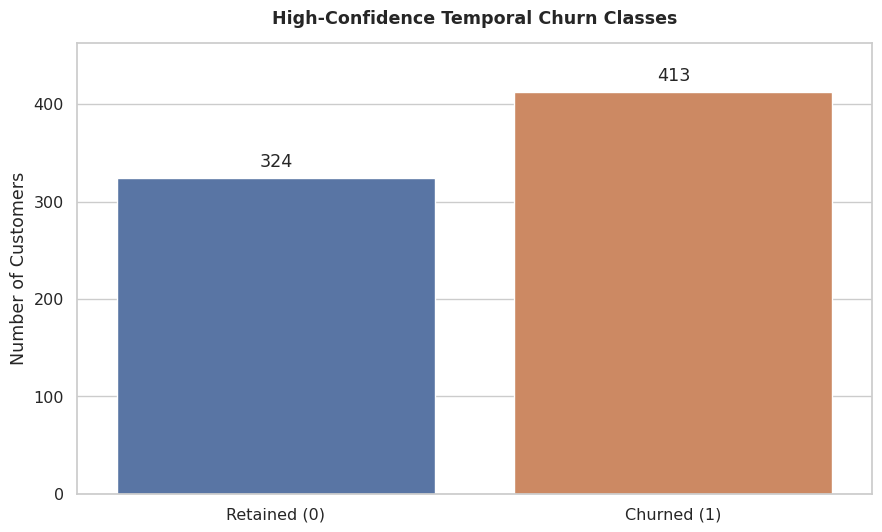

In [9]:

# Clean Seaborn class-distribution plot.
ax = sns.barplot(data=cohort_df, x="Class", y="Customers", hue="Class", legend=False)
ax.set_title("High-Confidence Temporal Churn Classes")
ax.set_xlabel("")
ax.set_ylabel("Number of Customers")
for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha="center", va="bottom", xytext=(0, 5), textcoords="offset points"
    )
publication_format(ax)
plt.show()



## 2. Individualized Purchase Behavior and Multi-Dimensional Feature Engineering

Because Online Retail II is transactional, the paper's customer concepts are reconstructed using genuine transactional evidence.

Derived variables:
- Purchase Frequency per month
- Average Order Value
- Spending Behavior
- Transaction Engagement components
- Purchase Efficiency = 1 - return rate
- CLV proxy
- Purchase Stability
- RFM score
- Transaction Engagement Index (TEI)
- Individualized Purchase Behavior (IPB) score


In [10]:

# Raw transaction-derived behavioral constructs.
months_observed = np.maximum(S_base[:, 6] / 30.44, 1.0)
years_observed = np.maximum(S_base[:, 6] / 365.25, 1.0/12.0)

purchase_frequency = S_base[:, 7] / months_observed
average_order_value = S_base[:, 8] / np.maximum(S_base[:, 7], 1.0)
spending_behavior = purchase_frequency * average_order_value

active_days_per_month = S_base[:, 10] / months_observed
purchase_lines_per_month = S_base[:, 9] / months_observed
recent_activity_ratio = S_base[:, 18] / 6.0

purchase_efficiency = np.clip(1.0 - S_base[:, 11], 0.0, 1.0)
clv_proxy = average_order_value * purchase_frequency * years_observed
purchase_stability_raw = purchase_frequency * purchase_efficiency

RAW_DERIVED_NAMES = [
    "Purchase_Frequency_per_Month",
    "Average_Order_Value",
    "Spending_Behavior",
    "Active_Days_per_Month",
    "Purchase_Lines_per_Month",
    "Recent_Activity_Ratio",
    "Purchase_Efficiency",
    "CLV_Proxy",
    "Purchase_Stability_Raw",
]

S_raw = np.column_stack([
    S_base,
    purchase_frequency,
    average_order_value,
    spending_behavior,
    active_days_per_month,
    purchase_lines_per_month,
    recent_activity_ratio,
    purchase_efficiency,
    clv_proxy,
    purchase_stability_raw,
]).astype(np.float32)

RAW_STATIC_NAMES = BASE_STATIC_FEATURES + RAW_DERIVED_NAMES

print("Raw static behavioral matrix:", S_raw.shape)


Raw static behavioral matrix: (737, 29)



## 3. Stratified 68% / 12% / 20% Split and Intelligent Preprocessing

The document specifies:
- 68% training,
- 12% validation,
- 20% test,
- stratification,
- Z-score outlier handling,
- Min-Max normalization.

To prevent leakage:
- outlier limits are estimated from **training data only**,
- Min-Max scalers are fit on **training data only**,
- validation/test are transformed with the training statistics.


In [12]:

# Missing-value safeguard.
missing_before = int(np.isnan(S_raw).sum() + np.isnan(X).sum())

# Mean imputation based on training data (only used if missing engineered values exist).
S_clean = S_raw.copy()
for j in range(S_clean.shape[1]):
    train_col = S_clean[train_idx, j]
    train_mean = np.nanmean(train_col)
    S_clean[np.isnan(S_clean[:, j]), j] = train_mean

X_clean = X.copy()
for j in range(X_clean.shape[2]):
    train_vals = X_clean[train_idx, :, j].reshape(-1)
    train_mean = np.nanmean(train_vals)
    feature_slice = X_clean[:, :, j]
    feature_slice[np.isnan(feature_slice)] = train_mean
    X_clean[:, :, j] = feature_slice

missing_after = int(np.isnan(S_clean).sum() + np.isnan(X_clean).sum())

# Z-score outlier replacement: clip values outside training mean ± 3 SD.
S_preclip = S_clean.copy()
X_preclip = X_clean.copy()

static_mu = S_clean[train_idx].mean(axis=0)
static_sd = S_clean[train_idx].std(axis=0) + 1e-6
static_z = np.abs((S_clean - static_mu) / static_sd)
outlier_customer_before = int((static_z > 3).any(axis=1).sum())

for j in range(S_clean.shape[1]):
    low = static_mu[j] - 3 * static_sd[j]
    high = static_mu[j] + 3 * static_sd[j]
    S_clean[:, j] = np.clip(S_clean[:, j], low, high)

for j in range(X_clean.shape[2]):
    vals = X_clean[train_idx, :, j].reshape(-1)
    mu = vals.mean()
    sd = vals.std() + 1e-6
    X_clean[:, :, j] = np.clip(X_clean[:, :, j], mu - 3*sd, mu + 3*sd)

static_z_after = np.abs((S_clean - static_mu) / static_sd)
outlier_customer_after = int((static_z_after > 3.00001).any(axis=1).sum())

# Min-Max normalization, fit on training data only.
sequence_scaler = MinMaxScaler()
sequence_scaler.fit(X_clean[train_idx].reshape(-1, X_clean.shape[-1]))
X_scaled = sequence_scaler.transform(
    X_clean.reshape(-1, X_clean.shape[-1])
).reshape(X_clean.shape).astype(np.float32)

static_scaler = MinMaxScaler()
static_scaler.fit(S_clean[train_idx])
S_scaled_base = static_scaler.transform(S_clean).astype(np.float32)

preprocess_report = pd.DataFrame({
    "Quality Metric": [
        "Missing numeric values",
        "Customer records with |Z| > 3",
        "Feature scale",
        "Class composition",
    ],
    "Before": [
        missing_before,
        outlier_customer_before,
        "Raw / heterogeneous units",
        f"Retained={(y==0).sum()}, Churned={(y==1).sum()}",
    ],
    "After": [
        missing_after,
        outlier_customer_after,
        "[0, 1] using train-fitted Min-Max",
        f"Retained={(y==0).sum()}, Churned={(y==1).sum()}",
    ],
})
display(preprocess_report)


,Quality Metric,Before,After
0,Missing numeric values,0,0
1,Customer records with |Z| > 3,90,0
2,Feature scale,Raw / heterogeneous units,"[0, 1] using train-fitted Min-Max"
3,Class composition,"Retained=324, Churned=413","Retained=324, Churned=413"


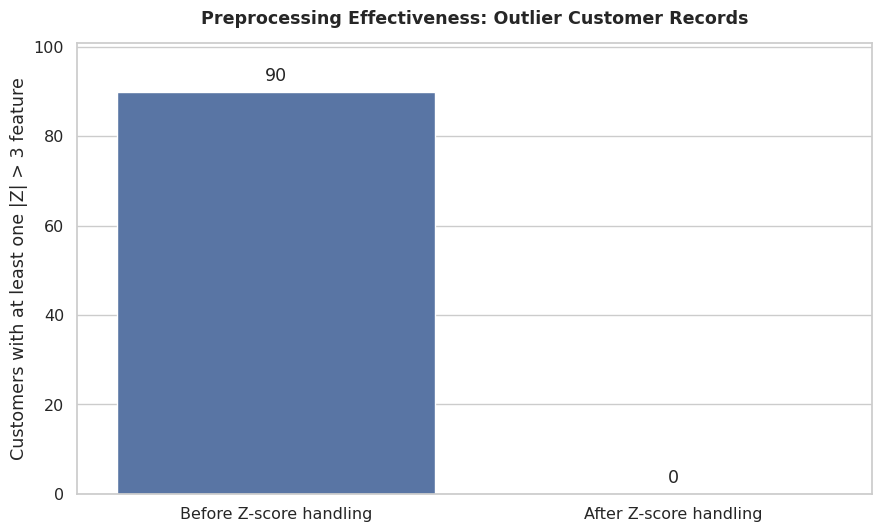

In [13]:

# Seaborn preprocessing-effectiveness plot: outlier customer records.
outlier_plot = pd.DataFrame({
    "Stage": ["Before Z-score handling", "After Z-score handling"],
    "Outlier Customers": [outlier_customer_before, outlier_customer_after],
})

ax = sns.barplot(
    data=outlier_plot,
    x="Stage", y="Outlier Customers",
    hue="Stage", legend=False
)
ax.set_title("Preprocessing Effectiveness: Outlier Customer Records")
ax.set_xlabel("")
ax.set_ylabel("Customers with at least one |Z| > 3 feature")
for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha="center", va="bottom", xytext=(0, 5), textcoords="offset points"
    )
plt.xticks(rotation=10)
publication_format(ax)
plt.show()


## 4. Exploratory Analysis of Individual Customer Behavior

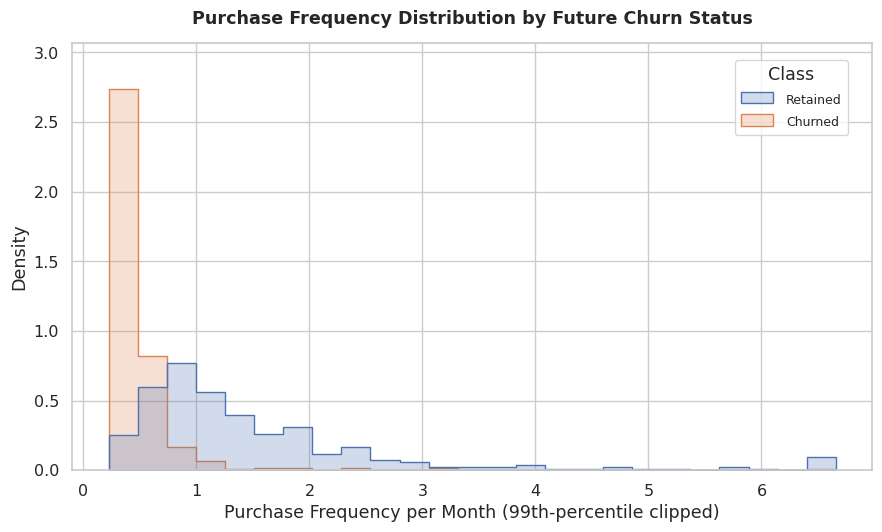

In [16]:

# Purchase frequency distribution.
plot_df = analysis_df.copy()
cap = plot_df["Purchase_Frequency_Raw"].quantile(0.99)
plot_df["Purchase_Frequency_Plot"] = plot_df["Purchase_Frequency_Raw"].clip(upper=cap)

ax = sns.histplot(
    data=plot_df,
    x="Purchase_Frequency_Plot",
    hue="Class",
    bins=25,
    element="step",
    stat="density",
    common_norm=False,
)
ax.set_title("Purchase Frequency Distribution by Future Churn Status")
ax.set_xlabel("Purchase Frequency per Month (99th-percentile clipped)")
ax.set_ylabel("Density")
publication_format(ax)
plt.show()


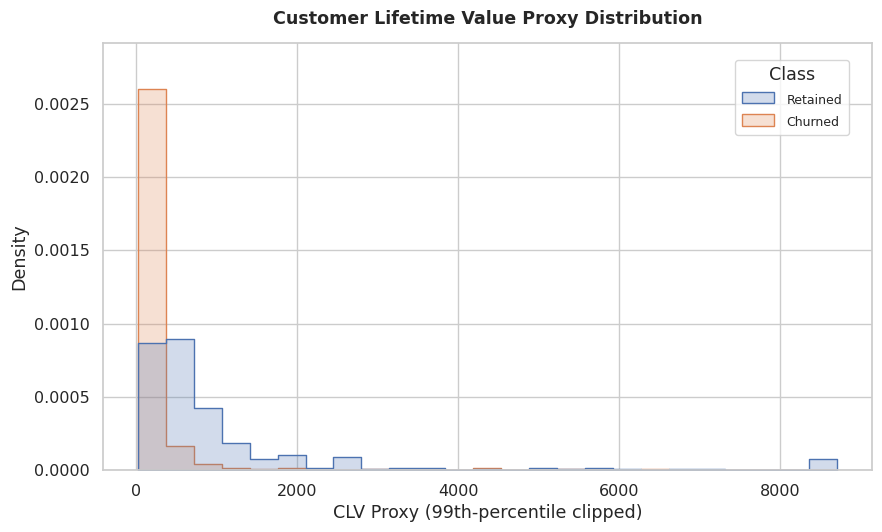

In [17]:

# CLV proxy distribution.
plot_df = analysis_df.copy()
cap = plot_df["CLV_Proxy_Raw"].quantile(0.99)
plot_df["CLV_Plot"] = plot_df["CLV_Proxy_Raw"].clip(upper=cap)

ax = sns.histplot(
    data=plot_df,
    x="CLV_Plot",
    hue="Class",
    bins=25,
    element="step",
    stat="density",
    common_norm=False,
)
ax.set_title("Customer Lifetime Value Proxy Distribution")
ax.set_xlabel("CLV Proxy (99th-percentile clipped)")
ax.set_ylabel("Density")
publication_format(ax)
plt.show()


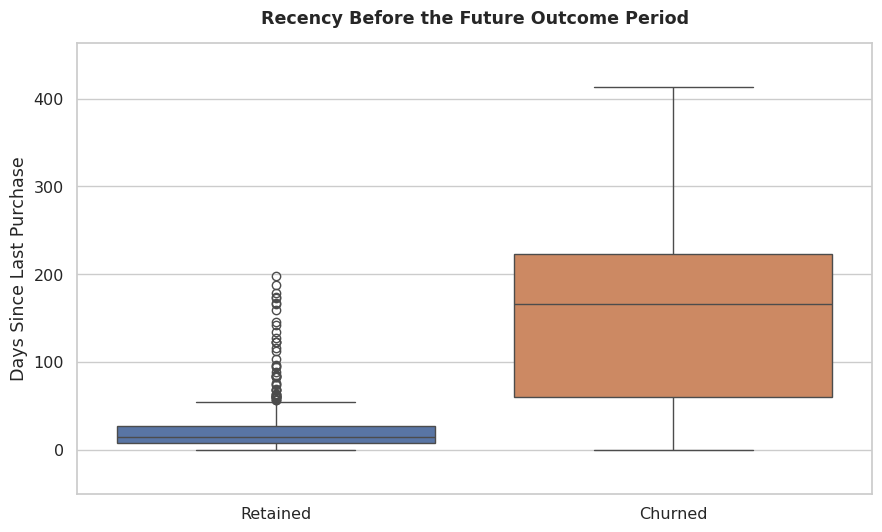

In [18]:

# Recency by churn status.
plot_df = analysis_df.copy()
cap = plot_df["Recency_Days_Raw"].quantile(0.99)
plot_df["Recency_Plot"] = plot_df["Recency_Days_Raw"].clip(upper=cap)

ax = sns.boxplot(
    data=plot_df, x="Class", y="Recency_Plot",
    hue="Class", legend=False
)
ax.set_title("Recency Before the Future Outcome Period")
ax.set_xlabel("")
ax.set_ylabel("Days Since Last Purchase")
publication_format(ax)
plt.show()


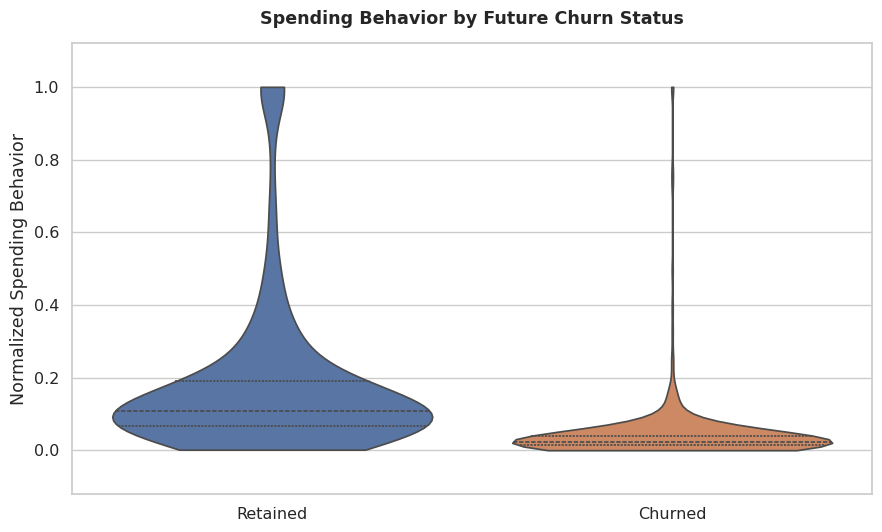

In [19]:

# Spending behavior by churn status.
plot_df = analysis_df.copy()
cap = plot_df["Spending_Behavior"].quantile(0.99)
plot_df["Spending_Behavior_Plot"] = plot_df["Spending_Behavior"].clip(upper=cap)

ax = sns.violinplot(
    data=plot_df, x="Class", y="Spending_Behavior_Plot",
    hue="Class", legend=False, inner="quartile", cut=0
)
ax.set_title("Spending Behavior by Future Churn Status")
ax.set_xlabel("")
ax.set_ylabel("Normalized Spending Behavior")
publication_format(ax)
plt.show()


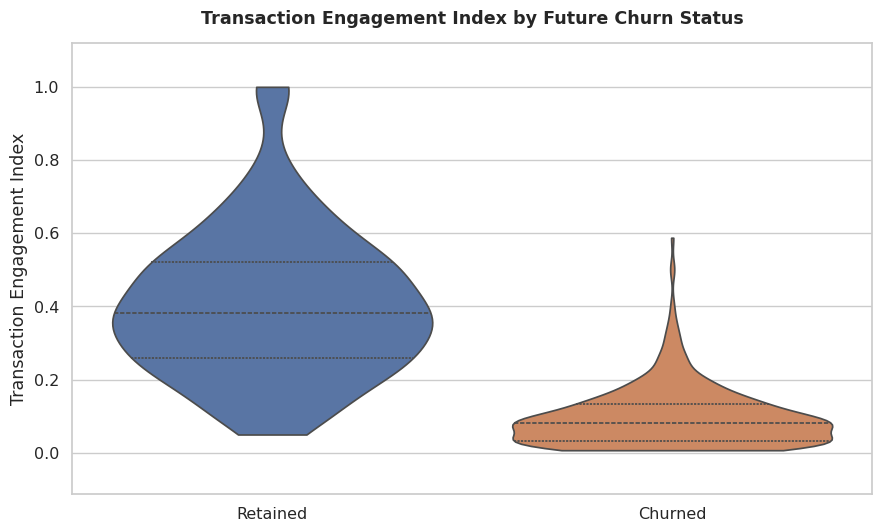

In [20]:

# Transaction-derived engagement index.
ax = sns.violinplot(
    data=analysis_df,
    x="Class", y="Transaction_Engagement_Index",
    hue="Class", legend=False,
    inner="quartile", cut=0
)
ax.set_title("Transaction Engagement Index by Future Churn Status")
ax.set_xlabel("")
ax.set_ylabel("Transaction Engagement Index")
publication_format(ax)
plt.show()


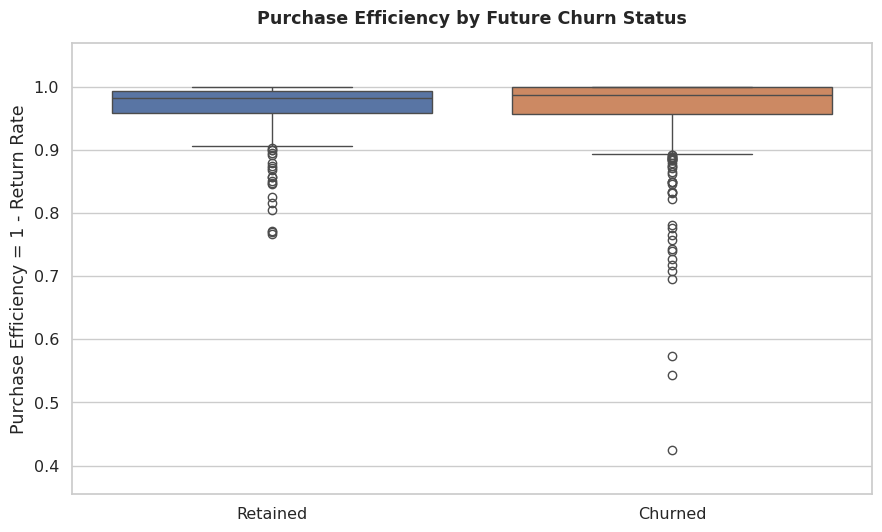

In [21]:

# Purchase efficiency.
ax = sns.boxplot(
    data=analysis_df,
    x="Class", y="Purchase_Efficiency_Raw",
    hue="Class", legend=False
)
ax.set_title("Purchase Efficiency by Future Churn Status")
ax.set_xlabel("")
ax.set_ylabel("Purchase Efficiency = 1 - Return Rate")
publication_format(ax)
plt.show()


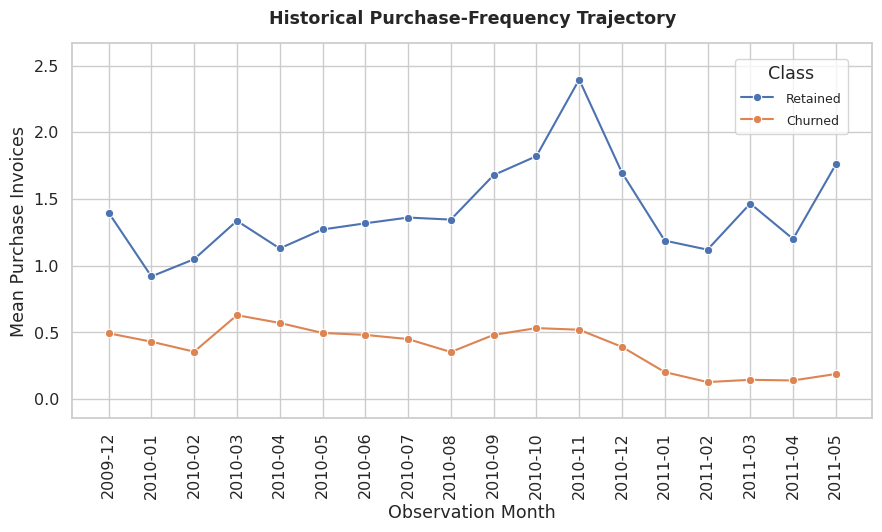

In [22]:

# Historical monthly purchase trajectory by future class.
months = pd.period_range("2009-12", periods=N_MONTHS, freq="M").astype(str)

rows = []
for cls, label in [(0, "Retained"), (1, "Churned")]:
    mean_invoices = X[y == cls, :, 0].mean(axis=0)
    for month, value in zip(months, mean_invoices):
        rows.append({"Month": month, "Mean Invoices": value, "Class": label})

trend_df = pd.DataFrame(rows)

ax = sns.lineplot(
    data=trend_df, x="Month", y="Mean Invoices",
    hue="Class", marker="o"
)
ax.set_title("Historical Purchase-Frequency Trajectory")
ax.set_xlabel("Observation Month")
ax.set_ylabel("Mean Purchase Invoices")
plt.xticks(rotation=0)
publication_format(ax)
plt.show()


## 5. Behavioral Correlation and Customer Segmentation

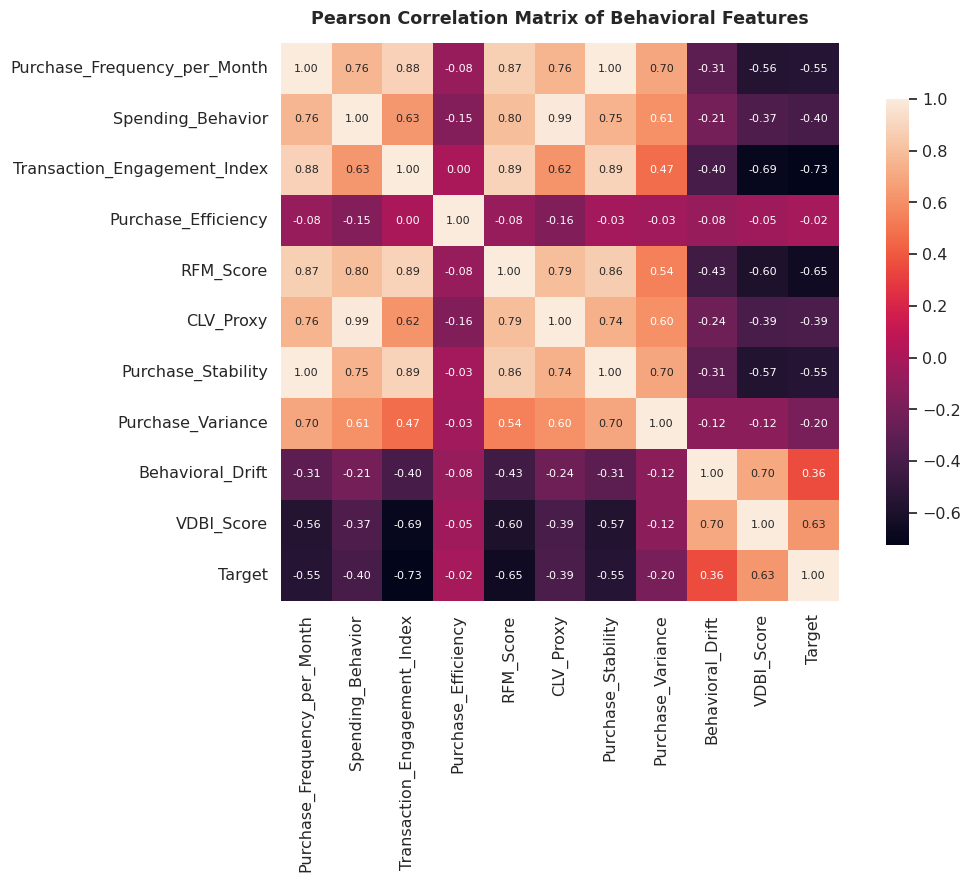

In [23]:

corr_features = [
    "Purchase_Frequency_per_Month",
    "Spending_Behavior",
    "Transaction_Engagement_Index",
    "Purchase_Efficiency",
    "RFM_Score",
    "CLV_Proxy",
    "Purchase_Stability",
    "Purchase_Variance",
    "Behavioral_Drift",
    "VDBI_Score",
    "Target",
]

corr = analysis_df[corr_features].corr(method="pearson")

plt.figure(figsize=(11, 9))
ax = sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    square=True,
    cbar_kws={"shrink": 0.8}
)
ax.set_title("Pearson Correlation Matrix of Behavioral Features")
plt.xticks(rotation=0)
plt.yticks(rotation=0)
publication_format(ax)
plt.show()


In [25]:

# Segment customers using quartiles of the Individualized Purchase Behavior score.
segment_labels = ["Low Engagement", "Moderate", "Active", "Highly Loyal"]
analysis_df["Segment"] = pd.qcut(
    analysis_df["IPB_Score"].rank(method="first"),
    q=4,
    labels=segment_labels
)

segment_table = (
    analysis_df.groupby("Segment", observed=False)
    .agg(
        Avg_Purchase_Frequency=("Purchase_Frequency_Raw", "mean"),
        Avg_Spending_Behavior=("Spending_Behavior", "mean"),
        Avg_Transaction_Engagement=("Transaction_Engagement_Index", "mean"),
        Avg_CLV=("CLV_Proxy_Raw", "mean"),
        Churn_Rate=("Target", "mean"),
    )
    .reset_index()
)

segment_table["Churn_Rate"] *= 100
display(segment_table.round(3))


,Segment,Avg_Purchase_Frequency,Avg_Spending_Behavior,Avg_Transaction_Engagement,Avg_CLV,Churn_Rate
0,Low Engagement,0.395,0.028,0.071,156.755005,92.432
1,Moderate,0.398,0.027,0.096,153.585999,85.326
2,Active,0.780,0.085,0.243,445.406006,40.217
3,Highly Loyal,2.299,0.283,0.525,2073.091064,5.978


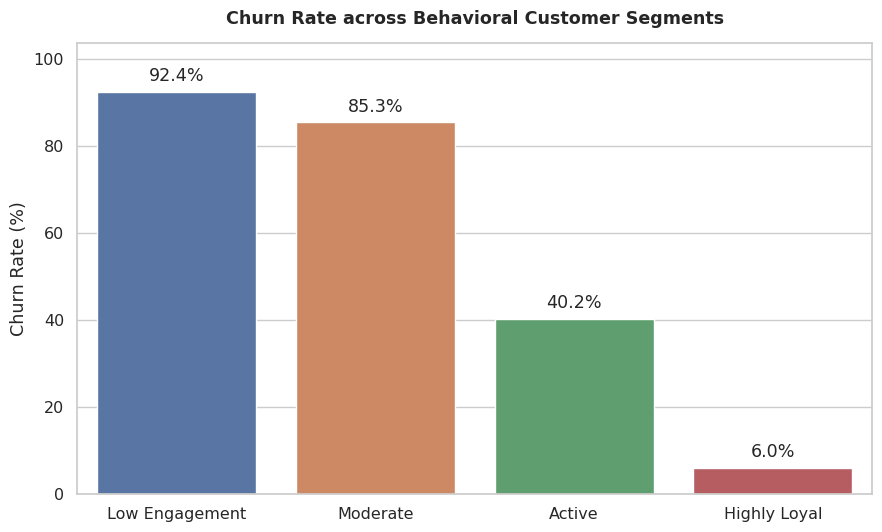

In [26]:

ax = sns.barplot(
    data=segment_table,
    x="Segment", y="Churn_Rate",
    hue="Segment", legend=False
)
ax.set_title("Churn Rate across Behavioral Customer Segments")
ax.set_xlabel("")
ax.set_ylabel("Churn Rate (%)")
for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.1f}%",
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha="center", va="bottom", xytext=(0, 5), textcoords="offset points"
    )
plt.xticks(rotation=0)
publication_format(ax)
plt.show()


## 6. Engineered Behavioral Feature Analysis

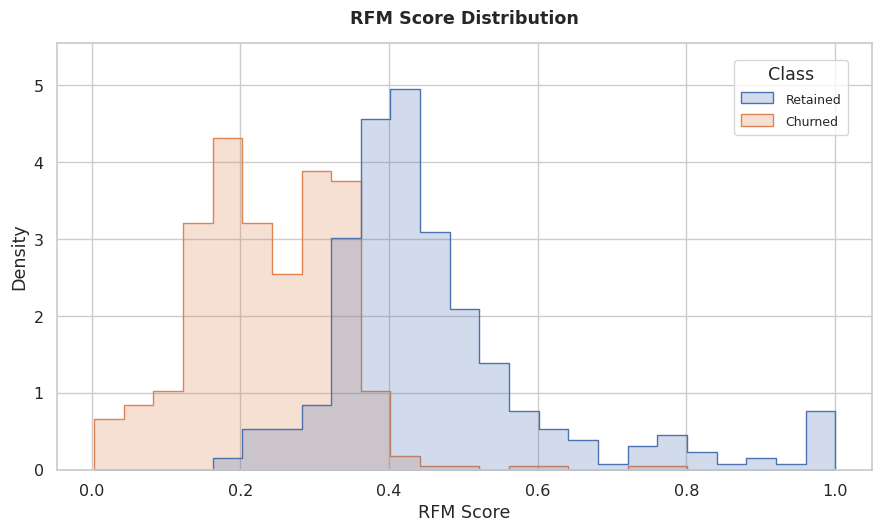

In [27]:

ax = sns.histplot(
    data=analysis_df,
    x="RFM_Score",
    hue="Class",
    bins=25,
    element="step",
    stat="density",
    common_norm=False
)
ax.set_title("RFM Score Distribution")
ax.set_xlabel("RFM Score")
ax.set_ylabel("Density")
publication_format(ax)
plt.show()


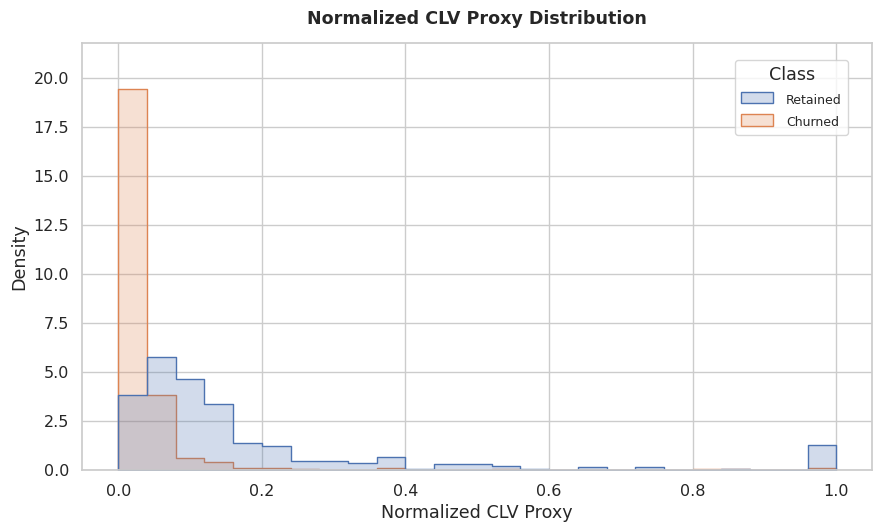

In [28]:

ax = sns.histplot(
    data=analysis_df,
    x="CLV_Proxy",
    hue="Class",
    bins=25,
    element="step",
    stat="density",
    common_norm=False
)
ax.set_title("Normalized CLV Proxy Distribution")
ax.set_xlabel("Normalized CLV Proxy")
ax.set_ylabel("Density")
publication_format(ax)
plt.show()


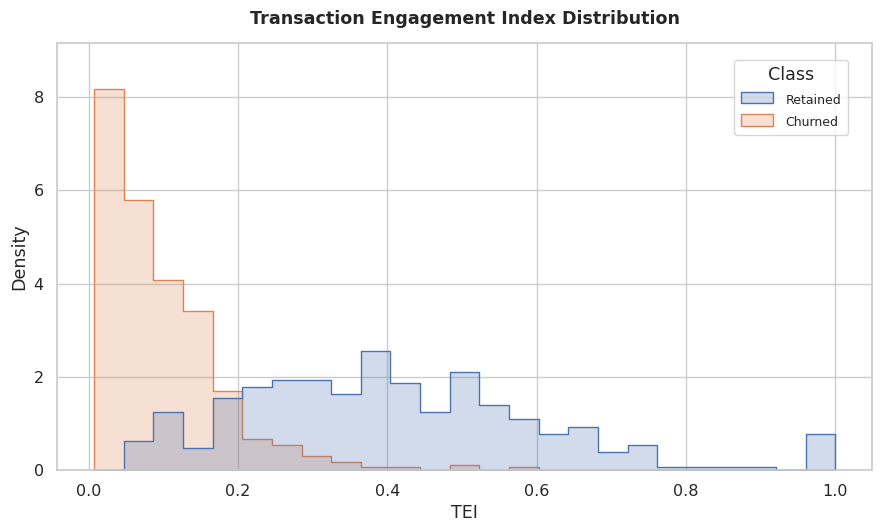

In [29]:

ax = sns.histplot(
    data=analysis_df,
    x="Transaction_Engagement_Index",
    hue="Class",
    bins=25,
    element="step",
    stat="density",
    common_norm=False
)
ax.set_title("Transaction Engagement Index Distribution")
ax.set_xlabel("TEI")
ax.set_ylabel("Density")
publication_format(ax)
plt.show()


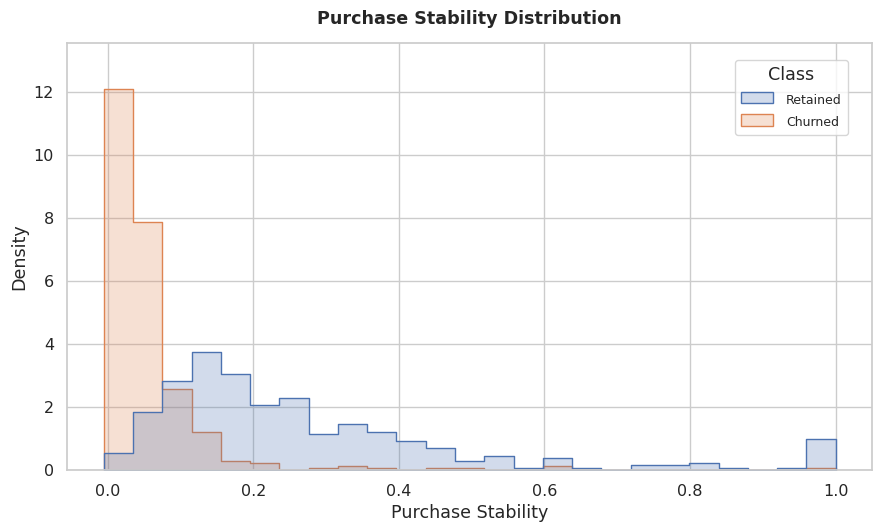

In [30]:

ax = sns.histplot(
    data=analysis_df,
    x="Purchase_Stability",
    hue="Class",
    bins=25,
    element="step",
    stat="density",
    common_norm=False
)
ax.set_title("Purchase Stability Distribution")
ax.set_xlabel("Purchase Stability")
ax.set_ylabel("Density")
publication_format(ax)
plt.show()


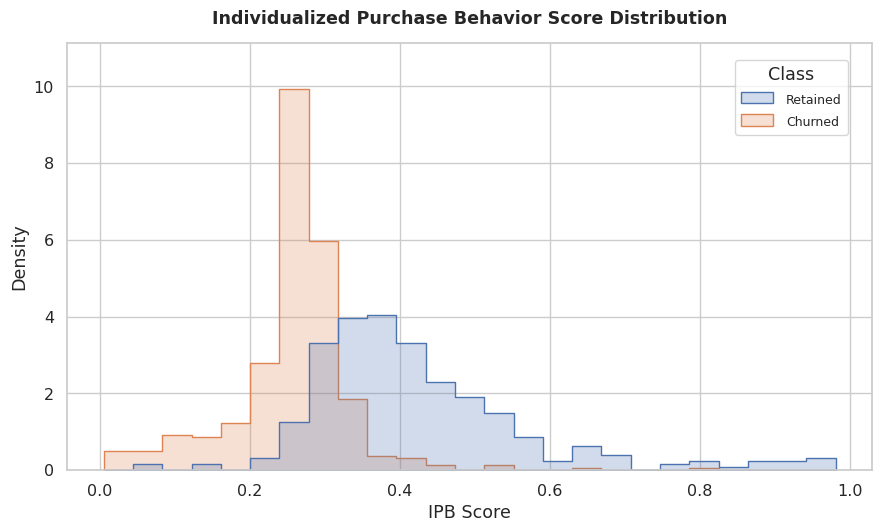

In [31]:

ax = sns.histplot(
    data=analysis_df,
    x="IPB_Score",
    hue="Class",
    bins=25,
    element="step",
    stat="density",
    common_norm=False
)
ax.set_title("Individualized Purchase Behavior Score Distribution")
ax.set_xlabel("IPB Score")
ax.set_ylabel("Density")
publication_format(ax)
plt.show()


In [32]:

# Univariate churn-discrimination table: original/transaction-derived vs engineered.
auc_candidates = {
    "Original/Derived": {
        "Total_Invoices": analysis_df["Total_Invoices"].values,
        "Average_Order_Value": analysis_df["Average_Order_Value"].values,
        "Recency_Days": analysis_df["Recency_Days"].values,
        "Return_Rate": analysis_df["Return_Rate_Total"].values,
        "Purchase_Frequency": analysis_df["Purchase_Frequency_per_Month"].values,
    },
    "Engineered": {
        "IPB_Score": analysis_df["IPB_Score"].values,
        "RFM_Score": analysis_df["RFM_Score"].values,
        "CLV_Proxy": analysis_df["CLV_Proxy"].values,
        "Transaction_Engagement_Index": analysis_df["Transaction_Engagement_Index"].values,
        "Purchase_Stability": analysis_df["Purchase_Stability"].values,
    },
}

auc_rows = []
for feature_type, features in auc_candidates.items():
    for name, values in features.items():
        auc = roc_auc_score(y, values)
        # Report discrimination independent of direction.
        discrimination_auc = max(auc, 1 - auc)
        auc_rows.append({
            "Feature Type": feature_type,
            "Feature": name,
            "Univariate AUC": discrimination_auc,
        })

univariate_auc_df = pd.DataFrame(auc_rows).sort_values("Univariate AUC", ascending=False)
display(univariate_auc_df.round(4))


,Feature Type,Feature,Univariate AUC
8,Engineered,Transaction_Engagement_Index,0.9460
6,Engineered,RFM_Score,0.9374
9,Engineered,Purchase_Stability,0.9217
4,Original/Derived,Purchase_Frequency,0.9199
0,Original/Derived,Total_Invoices,0.9081
5,Engineered,IPB_Score,0.9079
7,Engineered,CLV_Proxy,0.8820
2,Original/Derived,Recency_Days,0.8801
1,Original/Derived,Average_Order_Value,0.6659
3,Original/Derived,Return_Rate,0.5690


## 7. Variance-Driven Behavioral Intelligence (VDBI) Analysis

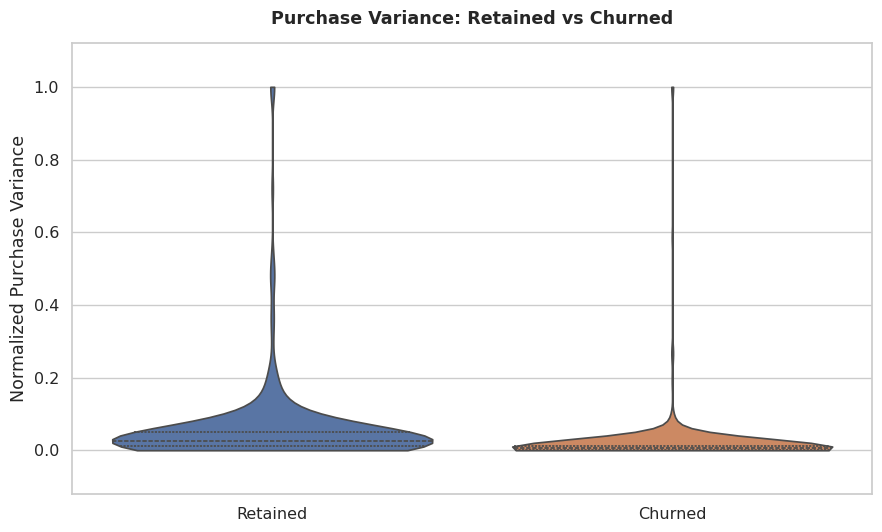

In [33]:

ax = sns.violinplot(
    data=analysis_df,
    x="Class", y="Purchase_Variance",
    hue="Class", legend=False,
    inner="quartile", cut=0
)
ax.set_title("Purchase Variance: Retained vs Churned")
ax.set_xlabel("")
ax.set_ylabel("Normalized Purchase Variance")
publication_format(ax)
plt.show()


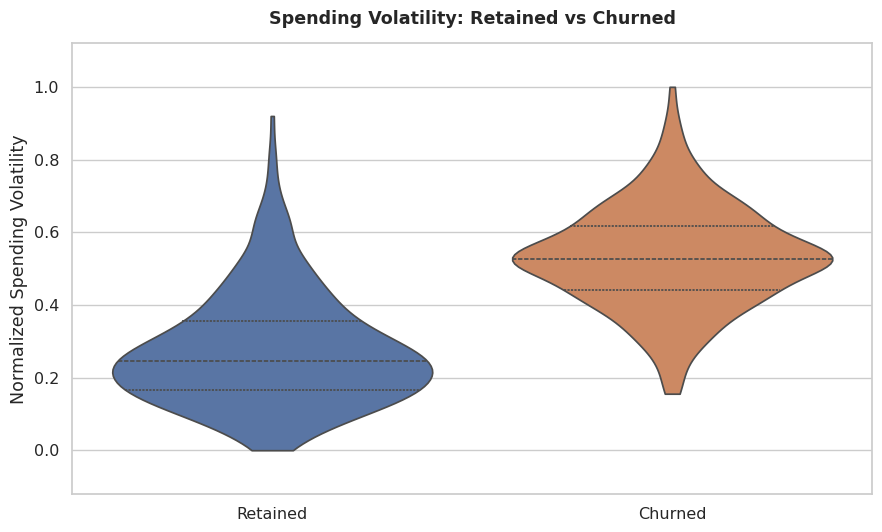

In [34]:

ax = sns.violinplot(
    data=analysis_df,
    x="Class", y="Spending_Volatility",
    hue="Class", legend=False,
    inner="quartile", cut=0
)
ax.set_title("Spending Volatility: Retained vs Churned")
ax.set_xlabel("")
ax.set_ylabel("Normalized Spending Volatility")
publication_format(ax)
plt.show()


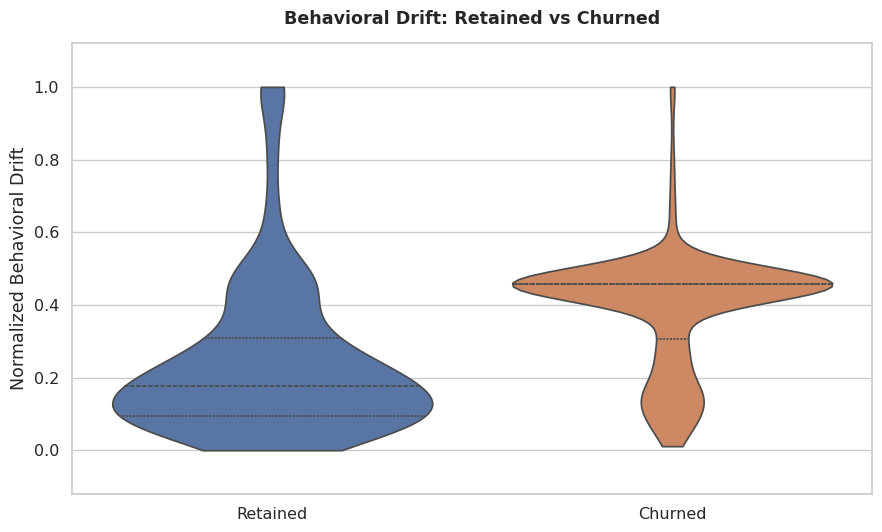

In [35]:

ax = sns.violinplot(
    data=analysis_df,
    x="Class", y="Behavioral_Drift",
    hue="Class", legend=False,
    inner="quartile", cut=0
)
ax.set_title("Behavioral Drift: Retained vs Churned")
ax.set_xlabel("")
ax.set_ylabel("Normalized Behavioral Drift")
publication_format(ax)
plt.show()


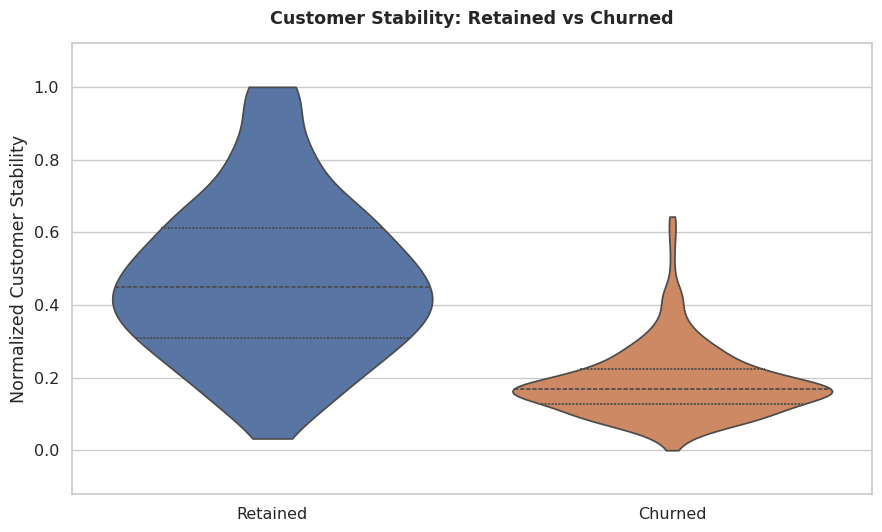

In [36]:

ax = sns.violinplot(
    data=analysis_df,
    x="Class", y="Customer_Stability",
    hue="Class", legend=False,
    inner="quartile", cut=0
)
ax.set_title("Customer Stability: Retained vs Churned")
ax.set_xlabel("")
ax.set_ylabel("Normalized Customer Stability")
publication_format(ax)
plt.show()


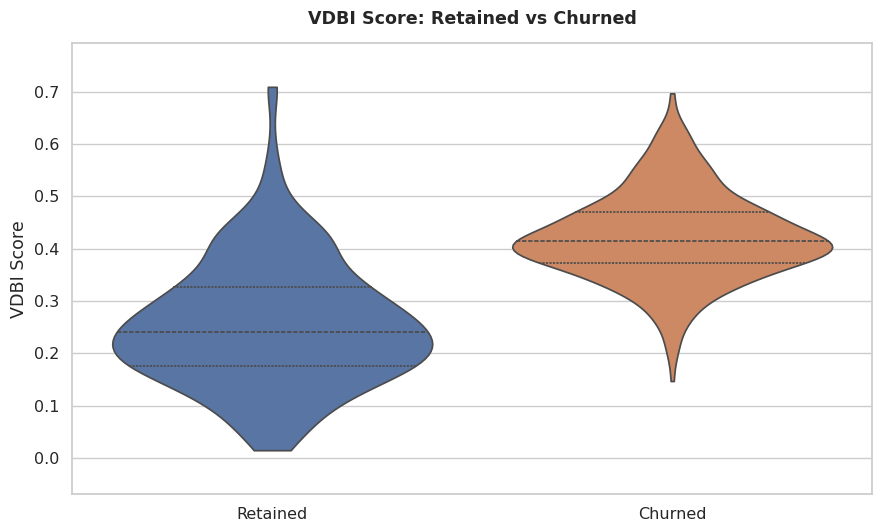

In [37]:

ax = sns.violinplot(
    data=analysis_df,
    x="Class", y="VDBI_Score",
    hue="Class", legend=False,
    inner="quartile", cut=0
)
ax.set_title("VDBI Score: Retained vs Churned")
ax.set_xlabel("")
ax.set_ylabel("VDBI Score")
publication_format(ax)
plt.show()



## 8. Proposed VBTNet

Document-aligned settings:
- **5 attention heads**
- **d_model = 10**
- **d_k = 10 / 5 = 2**
- initial adaptive fusion weight **λ = 0.60**
- Softmax output for Active/Churned classes.

The VBTNet first creates temporal behavioral embeddings and explicit Query/Key/Value attention internally through PyTorch's multi-head attention layer. A VDBI/static branch is then adaptively fused with the contextual Transformer representation.


In [39]:

ATTENTION_HEADS = 5
D_MODEL = 10
D_K = D_MODEL // ATTENTION_HEADS
INITIAL_FUSION_LAMBDA = 0.60

class VBTEncoderBlock(nn.Module):
    def __init__(self, d_model=10, n_heads=5, dropout=0.10):
        super().__init__()
        self.attention = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=n_heads,
            dropout=dropout,
            batch_first=True,
        )
        self.norm1 = nn.LayerNorm(d_model)
        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, 40),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(40, d_model),
        )
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, return_attention=False):
        attn_out, attn_weights = self.attention(
            x, x, x,
            need_weights=return_attention,
            average_attn_weights=False,
        )
        x = self.norm1(x + self.dropout(attn_out))
        x = self.norm2(x + self.dropout(self.feed_forward(x)))
        return x, attn_weights


class VDBIVBTNet(nn.Module):
    def __init__(self, seq_features, static_features, n_months):
        super().__init__()

        self.sequence_projection = nn.Linear(seq_features, D_MODEL)
        self.positional_embedding = nn.Parameter(
            torch.randn(1, n_months, D_MODEL) * 0.02
        )
        self.cls_token = nn.Parameter(torch.randn(1, 1, D_MODEL) * 0.02)

        self.encoder1 = VBTEncoderBlock(D_MODEL, ATTENTION_HEADS)
        self.encoder2 = VBTEncoderBlock(D_MODEL, ATTENTION_HEADS)

        self.transformer_projection = nn.Sequential(
            nn.Linear(D_MODEL, 48),
            nn.GELU(),
        )

        self.vdbi_projection = nn.Sequential(
            nn.Linear(static_features, 64),
            nn.GELU(),
            nn.Dropout(0.12),
            nn.Linear(64, 48),
            nn.GELU(),
        )

        # Adaptive scalar initialized at lambda=0.60.
        initial_logit = np.log(INITIAL_FUSION_LAMBDA / (1 - INITIAL_FUSION_LAMBDA))
        self.lambda_logit = nn.Parameter(
            torch.tensor(float(initial_logit), dtype=torch.float32)
        )

        self.classifier = nn.Sequential(
            nn.LayerNorm(48),
            nn.Linear(48, 32),
            nn.GELU(),
            nn.Dropout(0.10),
            nn.Linear(32, 2),
        )

    def forward(self, sequence, behavioral_features,
                return_attention=False, return_representations=False):
        z = self.sequence_projection(sequence) + self.positional_embedding
        cls = self.cls_token.expand(sequence.size(0), -1, -1)
        z = torch.cat([cls, z], dim=1)

        z, attn1 = self.encoder1(z, return_attention=return_attention)
        z, attn2 = self.encoder2(z, return_attention=return_attention)

        transformer_repr = self.transformer_projection(z[:, 0])
        vdbi_repr = self.vdbi_projection(behavioral_features)

        fusion_lambda = torch.sigmoid(self.lambda_logit)
        fused_repr = (
            fusion_lambda * transformer_repr +
            (1.0 - fusion_lambda) * vdbi_repr
        )

        logits = self.classifier(fused_repr)

        if return_attention or return_representations:
            return logits, attn1, attn2, transformer_repr, vdbi_repr, fused_repr

        return logits


model = VDBIVBTNet(
    seq_features=X_scaled.shape[-1],
    static_features=S_model.shape[-1],
    n_months=X_scaled.shape[1],
)

print(model)
print("Attention heads:", ATTENTION_HEADS)
print("Embedding dimension (d_model):", D_MODEL)
print("Per-head d_k:", D_K)
print("Initial fusion lambda:", INITIAL_FUSION_LAMBDA)
print("Trainable parameters:", f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")


VDBIVBTNet(
  (sequence_projection): Linear(in_features=7, out_features=10, bias=True)
  (encoder1): VBTEncoderBlock(
    (attention): MultiheadAttention(
      (out_proj): NonDynamicallyQuantizableLinear(in_features=10, out_features=10, bias=True)
    )
    (norm1): LayerNorm((10,), eps=1e-05, elementwise_affine=True)
    (feed_forward): Sequential(
      (0): Linear(in_features=10, out_features=40, bias=True)
      (1): GELU(approximate='none')
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=40, out_features=10, bias=True)
    )
    (norm2): LayerNorm((10,), eps=1e-05, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder2): VBTEncoderBlock(
    (attention): MultiheadAttention(
      (out_proj): NonDynamicallyQuantizableLinear(in_features=10, out_features=10, bias=True)
    )
    (norm1): LayerNorm((10,), eps=1e-05, elementwise_affine=True)
    (feed_forward): Sequential(
      (0): Linear(in_features=10, out_features=40, bias=Tru

## 9. VDBI-VBTNet Training

In [40]:

def make_loader(idx, shuffle=False):
    return DataLoader(
        TensorDataset(
            torch.tensor(X_scaled[idx], dtype=torch.float32),
            torch.tensor(S_model[idx], dtype=torch.float32),
            torch.tensor(y[idx], dtype=torch.long),
        ),
        batch_size=64,
        shuffle=shuffle,
    )

train_loader = make_loader(train_idx, shuffle=True)
val_loader = make_loader(val_idx, shuffle=False)
test_loader = make_loader(test_idx, shuffle=False)

torch.manual_seed(SEED)
np.random.seed(SEED)

model = VDBIVBTNet(
    seq_features=X_scaled.shape[-1],
    static_features=S_model.shape[-1],
    n_months=X_scaled.shape[1],
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=8e-4,
    weight_decay=1e-4,
)

history = []
best_val_auc = -np.inf
best_state = None
patience = 18
wait = 0
MAX_EPOCHS = 160

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    train_loss = 0.0

    for seq_b, static_b, y_b in train_loader:
        optimizer.zero_grad()

        logits = model(seq_b, static_b)
        loss = criterion(logits, y_b)

        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        train_loss += loss.item() * len(y_b)

    train_loss /= len(train_idx)

    model.eval()
    val_loss = 0.0
    val_probs = []
    val_true = []

    with torch.no_grad():
        for seq_b, static_b, y_b in val_loader:
            logits = model(seq_b, static_b)
            loss = criterion(logits, y_b)
            probs = torch.softmax(logits, dim=1)[:, 1]

            val_loss += loss.item() * len(y_b)
            val_probs.extend(probs.cpu().numpy())
            val_true.extend(y_b.cpu().numpy())

    val_loss /= len(val_idx)
    val_auc = roc_auc_score(val_true, val_probs)

    history.append({
        "Epoch": epoch,
        "Train_Loss": train_loss,
        "Validation_Loss": val_loss,
        "Validation_AUC": val_auc,
    })

    if val_auc > best_val_auc + 1e-4:
        best_val_auc = val_auc
        best_state = {
            k: v.detach().clone()
            for k, v in model.state_dict().items()
        }
        wait = 0
    else:
        wait += 1

    if wait >= patience:
        break

model.load_state_dict(best_state)
history_df = pd.DataFrame(history)

learned_lambda = float(torch.sigmoid(model.lambda_logit).detach().cpu())

print("Training completed.")
print("Epochs executed:", len(history_df))
print("Best validation ROC-AUC:", round(best_val_auc, 4))
print("Initial fusion lambda:", INITIAL_FUSION_LAMBDA)
print("Learned adaptive fusion lambda:", round(learned_lambda, 4))


Training completed.
Epochs executed: 38
Best validation ROC-AUC: 0.98
Initial fusion lambda: 0.6
Learned adaptive fusion lambda: 0.5836



## 10. Decision-Threshold Analysis

The paper's algorithm converts churn probability into a class using a decision threshold.  
This implementation uses the standard **0.50 Softmax decision boundary** for final evaluation and visualizes validation trade-offs across thresholds.


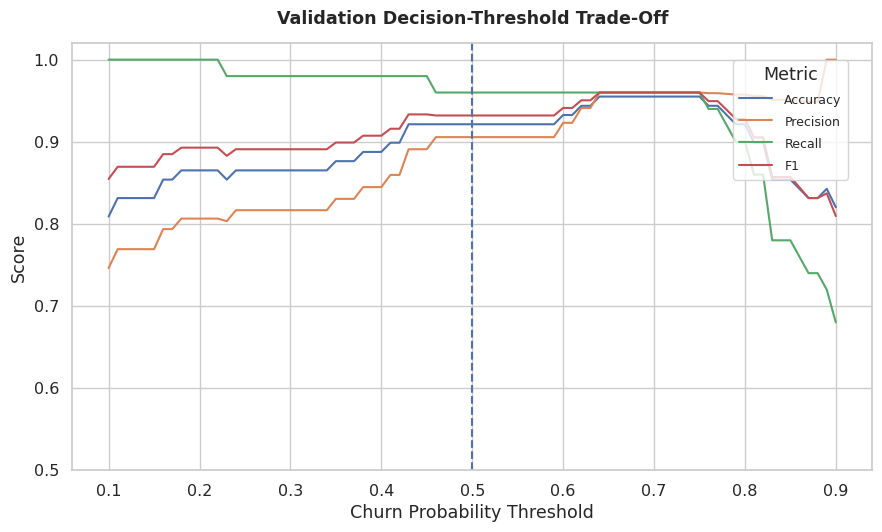

In [43]:

def predict_probabilities(loader, return_repr=False):
    probabilities = []
    truths = []
    fused_representations = []
    transformer_representations = []
    vdbi_representations = []
    attn1_all = []
    attn2_all = []

    model.eval()

    with torch.no_grad():
        for seq_b, static_b, y_b in loader:
            if return_repr:
                outputs = model(
                    seq_b, static_b,
                    return_attention=True,
                    return_representations=True,
                )
                logits, attn1, attn2, t_repr, v_repr, f_repr = outputs

                fused_representations.append(f_repr.cpu().numpy())
                transformer_representations.append(t_repr.cpu().numpy())
                vdbi_representations.append(v_repr.cpu().numpy())
                attn1_all.append(attn1.cpu().numpy())
                attn2_all.append(attn2.cpu().numpy())
            else:
                logits = model(seq_b, static_b)

            probs = torch.softmax(logits, dim=1)[:, 1]
            probabilities.extend(probs.cpu().numpy())
            truths.extend(y_b.cpu().numpy())

    if return_repr:
        return (
            np.asarray(probabilities),
            np.asarray(truths, dtype=int),
            np.vstack(fused_representations),
            np.vstack(transformer_representations),
            np.vstack(vdbi_representations),
            np.concatenate(attn1_all, axis=0),
            np.concatenate(attn2_all, axis=0),
        )

    return np.asarray(probabilities), np.asarray(truths, dtype=int)


val_probs, val_true = predict_probabilities(val_loader)

threshold_rows = []
for threshold in np.linspace(0.10, 0.90, 81):
    pred = (val_probs >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(val_true, pred),
        "Precision": precision_score(val_true, pred, zero_division=0),
        "Recall": recall_score(val_true, pred, zero_division=0),
        "F1": f1_score(val_true, pred, zero_division=0),
    })

threshold_df = pd.DataFrame(threshold_rows)
threshold_long = threshold_df.melt(
    id_vars="Threshold",
    var_name="Metric",
    value_name="Score",
)

FINAL_THRESHOLD = 0.50

ax = sns.lineplot(
    data=threshold_long,
    x="Threshold", y="Score", hue="Metric"
)
ax.axvline(
    FINAL_THRESHOLD,
    linestyle="--",
    linewidth=1.5,
    label="Final threshold = 0.50"
)
ax.set_title("Validation Decision-Threshold Trade-Off")
ax.set_xlabel("Churn Probability Threshold")
ax.set_ylabel("Score")
ax.set_ylim(0.50, 1.02)
publication_format(ax)
plt.show()


## 11. Final Held-Out Test Evaluation

## 12. VBTNet Attention and Representation-Learning Analysis

In [53]:

# Attention-head statistics from the first VBTNet encoder.
# Shape: customers x heads x query_tokens x key_tokens.
eps = 1e-12

head_mean = attn1.mean(axis=(0, 2, 3))
head_max = attn1.max(axis=(0, 2, 3))
entropy_per_query = -(attn1 * np.log(attn1 + eps)).sum(axis=-1)
head_entropy = entropy_per_query.mean(axis=(0, 2))

attention_stats_df = pd.DataFrame({
    "Attention Head": [f"Head {i+1}" for i in range(ATTENTION_HEADS)],
    "Mean Attention Weight": head_mean,
    "Max Attention Weight": head_max,
    "Attention Entropy": head_entropy,
})

display(attention_stats_df.round(4))


,Attention Head,Mean Attention Weight,Max Attention Weight,Attention Entropy
0,Head 1,0.0526,0.0637,2.9443
1,Head 2,0.0526,0.0573,2.9444
2,Head 3,0.0526,0.0678,2.9443
3,Head 4,0.0526,0.0733,2.9438
4,Head 5,0.0526,0.0571,2.9444


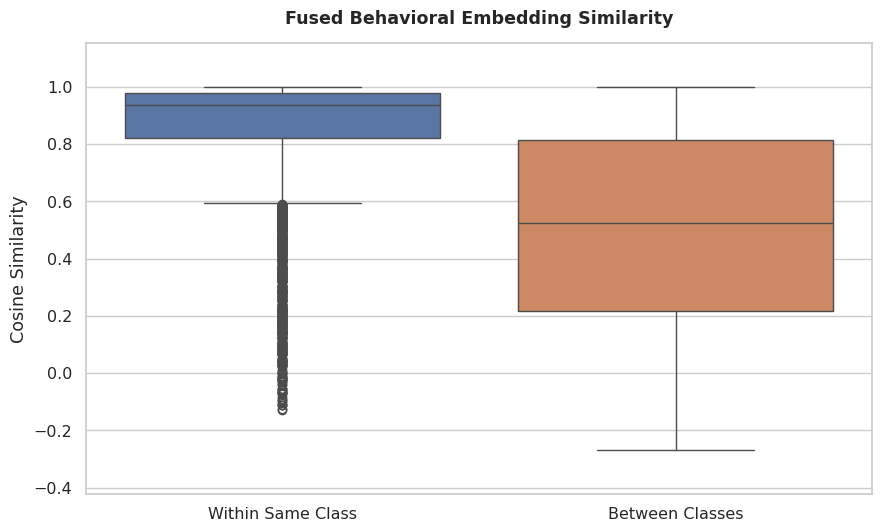

In [55]:

# Representation similarity: within-class vs between-class cosine similarity.
sim = cosine_similarity(fused_repr)

within_values = []
between_values = []

for i in range(len(test_true)):
    for j in range(i + 1, len(test_true)):
        if test_true[i] == test_true[j]:
            within_values.append(sim[i, j])
        else:
            between_values.append(sim[i, j])

similarity_df = pd.DataFrame({
    "Cosine Similarity": np.r_[within_values, between_values],
    "Pair Type": (
        ["Within Same Class"] * len(within_values) +
        ["Between Classes"] * len(between_values)
    ),
})

ax = sns.boxplot(
    data=similarity_df,
    x="Pair Type", y="Cosine Similarity",
    hue="Pair Type", legend=False
)
ax.set_title("Fused Behavioral Embedding Similarity")
ax.set_xlabel("")
ax.set_ylabel("Cosine Similarity")
publication_format(ax)
plt.show()


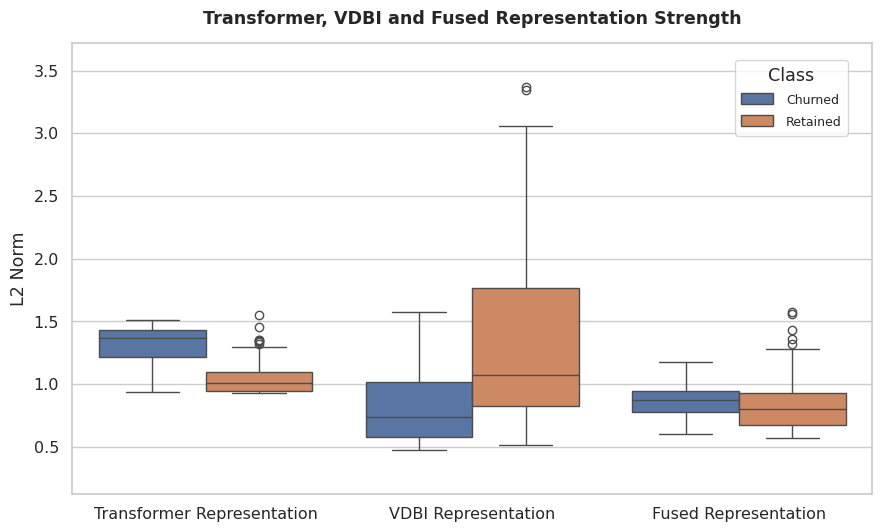

In [56]:

# Feature-fusion representation norms.
fusion_norm_df = pd.DataFrame({
    "Transformer Representation": np.linalg.norm(transformer_repr, axis=1),
    "VDBI Representation": np.linalg.norm(vdbi_repr, axis=1),
    "Fused Representation": np.linalg.norm(fused_repr, axis=1),
    "Class": np.where(test_true == 1, "Churned", "Retained"),
})

fusion_long = fusion_norm_df.melt(
    id_vars="Class",
    var_name="Representation",
    value_name="L2 Norm",
)

ax = sns.boxplot(
    data=fusion_long,
    x="Representation", y="L2 Norm",
    hue="Class"
)
ax.set_title("Transformer, VDBI and Fused Representation Strength")
ax.set_xlabel("")
ax.set_ylabel("L2 Norm")
plt.xticks(rotation=10)
publication_format(ax)
plt.show()


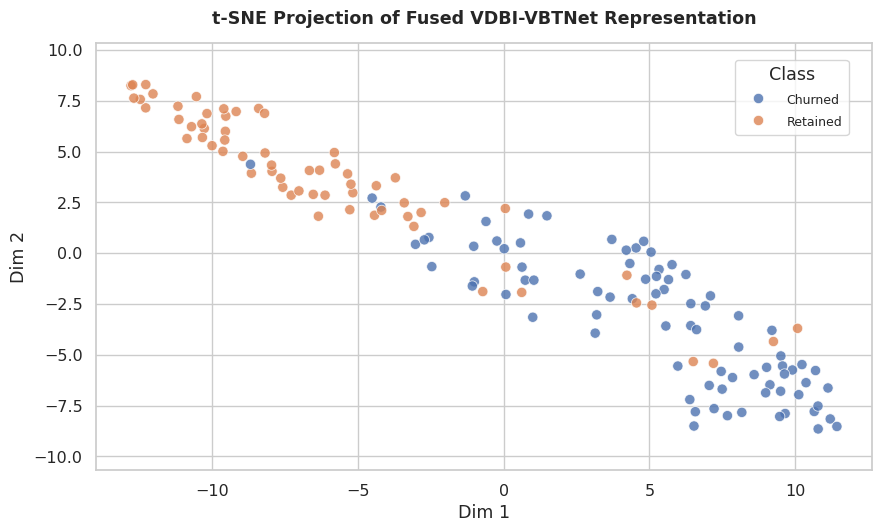

In [57]:

# t-SNE latent-space projection.
perplexity = min(30, max(5, len(fused_repr) // 5))
tsne = TSNE(
    n_components=2,
    perplexity=perplexity,
    random_state=SEED,
    init="pca",
    learning_rate="auto",
)
tsne_xy = tsne.fit_transform(fused_repr)

tsne_df = pd.DataFrame({
    "Dim 1": tsne_xy[:, 0],
    "Dim 2": tsne_xy[:, 1],
    "Class": np.where(test_true == 1, "Churned", "Retained"),
})

ax = sns.scatterplot(
    data=tsne_df,
    x="Dim 1", y="Dim 2",
    hue="Class",
    s=55,
    alpha=0.8,
)
ax.set_title("t-SNE Projection of Fused VDBI-VBTNet Representation")
publication_format(ax)
plt.show()


## 13. Proposed-Model Feature Importance

## 14. Save Complete Executed Artifacts

In [62]:

artifact_dir = Path("/mnt/data")

model_path = artifact_dir / "VDBI_VBTNet_Visual_Corrected_Model.pt"
metrics_path = artifact_dir / "VDBI_VBTNet_Visual_Corrected_Metrics.csv"
predictions_path = artifact_dir / "VDBI_VBTNet_Visual_Corrected_Predictions.csv"
attention_path = artifact_dir / "VDBI_VBTNet_Visual_Corrected_Attention_Statistics.csv"
feature_importance_path = artifact_dir / "VDBI_VBTNet_Visual_Corrected_Feature_Importance.csv"

torch.save({
    "model_state_dict": model.state_dict(),
    "threshold": FINAL_THRESHOLD,
    "seed": SEED,
    "attention_heads": ATTENTION_HEADS,
    "d_model": D_MODEL,
    "d_k": D_K,
    "initial_fusion_lambda": INITIAL_FUSION_LAMBDA,
    "learned_fusion_lambda": learned_lambda,
    "sequence_features": SEQ_FEATURES,
    "static_features": STATIC_FEATURE_NAMES,
    "sequence_scaler_min": sequence_scaler.min_,
    "sequence_scaler_scale": sequence_scaler.scale_,
    "static_scaler_min": static_scaler.min_,
    "static_scaler_scale": static_scaler.scale_,
}, model_path)

metrics_df.to_csv(metrics_path, index=False)
predictions_df.to_csv(predictions_path, index=False)
attention_stats_df.to_csv(attention_path, index=False)

feature_importance_summary = (
    shap_df
    .merge(permutation_df, on="Feature", how="outer")
    .merge(information_gain_df, on="Feature", how="outer")
)
feature_importance_summary.to_csv(feature_importance_path, index=False)

print("Saved proposed model:", model_path)
print("Saved metrics:", metrics_path)
print("Saved predictions:", predictions_path)
print("Saved attention statistics:", attention_path)
print("Saved feature-importance summary:", feature_importance_path)


Saved proposed model: /mnt/data/VDBI_VBTNet_Visual_Corrected_Model.pt
Saved metrics: /mnt/data/VDBI_VBTNet_Visual_Corrected_Metrics.csv
Saved predictions: /mnt/data/VDBI_VBTNet_Visual_Corrected_Predictions.csv
Saved attention statistics: /mnt/data/VDBI_VBTNet_Visual_Corrected_Attention_Statistics.csv
Saved feature-importance summary: /mnt/data/VDBI_VBTNet_Visual_Corrected_Feature_Importance.csv



## Final Research Interpretation

This executed notebook implements the supplied paper's **core proposed methodology** with the UCI Online Retail II dataset:

**Transaction history → Individualized Purchase Behavior → RFM/CLV/TEI/Purchase Stability/IPB → VDBI → 5-head VBTNet → Adaptive Fusion → Softmax Churn Probability → Risk Intelligence**

The implementation deliberately does **not** create synthetic login, email, session, mobile-app, social-media or cart-abandonment values. The paper's engagement concept is therefore represented with a transparent **Transaction Engagement Index** derived only from the available transactional evidence.

No baseline model is trained. The performance, attention analysis, latent-space analysis, feature importance, calibration, threshold analysis and confusion matrices all belong to the proposed VDBI-VBTNet.
